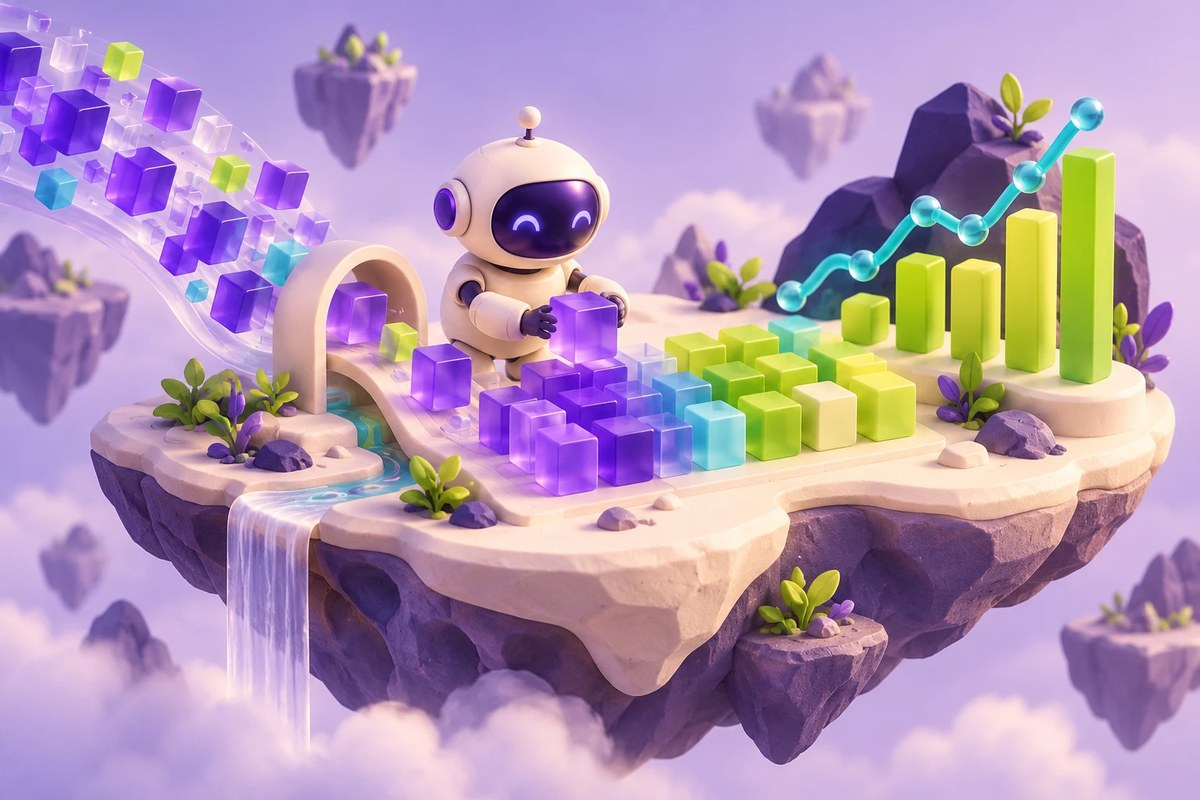

AI PATH · Python для машинного обучения · Урок 039

# Pandas: индексы, выборки и изменение таблиц

Метки строк, позиции и копии на небольших обозримых примерах.

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-039-goal"></a>
## Что вы разберёте

Выбирать строки и столбцы без путаницы между именем индекса и его позицией.

### Перед началом

- Списки и срезы Python
- Базовые массивы NumPy

### Что понадобится

- Pandas и NumPy
- Встроенные примеры и случайные таблицы; внешние файлы не требуются

## Навигация по уроку

- [Цель и подготовка](#ai-039-goal)
- [Карта урока](#ai-039-map)
- [Таблица с датами](#ai-039-section-01)
- [Копия и изменение](#ai-039-section-02)
- [Создание столбца](#ai-039-section-03)
- [Срезы](#ai-039-section-04)
- [Временной индекс](#ai-039-section-05)
- [Выборка loc](#ai-039-section-06)
- [Две оси сразу](#ai-039-section-07)
- [Проверьте понимание](#ai-039-practice)
- [Источники и ограничения](#ai-039-provenance)

<a id="ai-039-map"></a>
## Карта урока

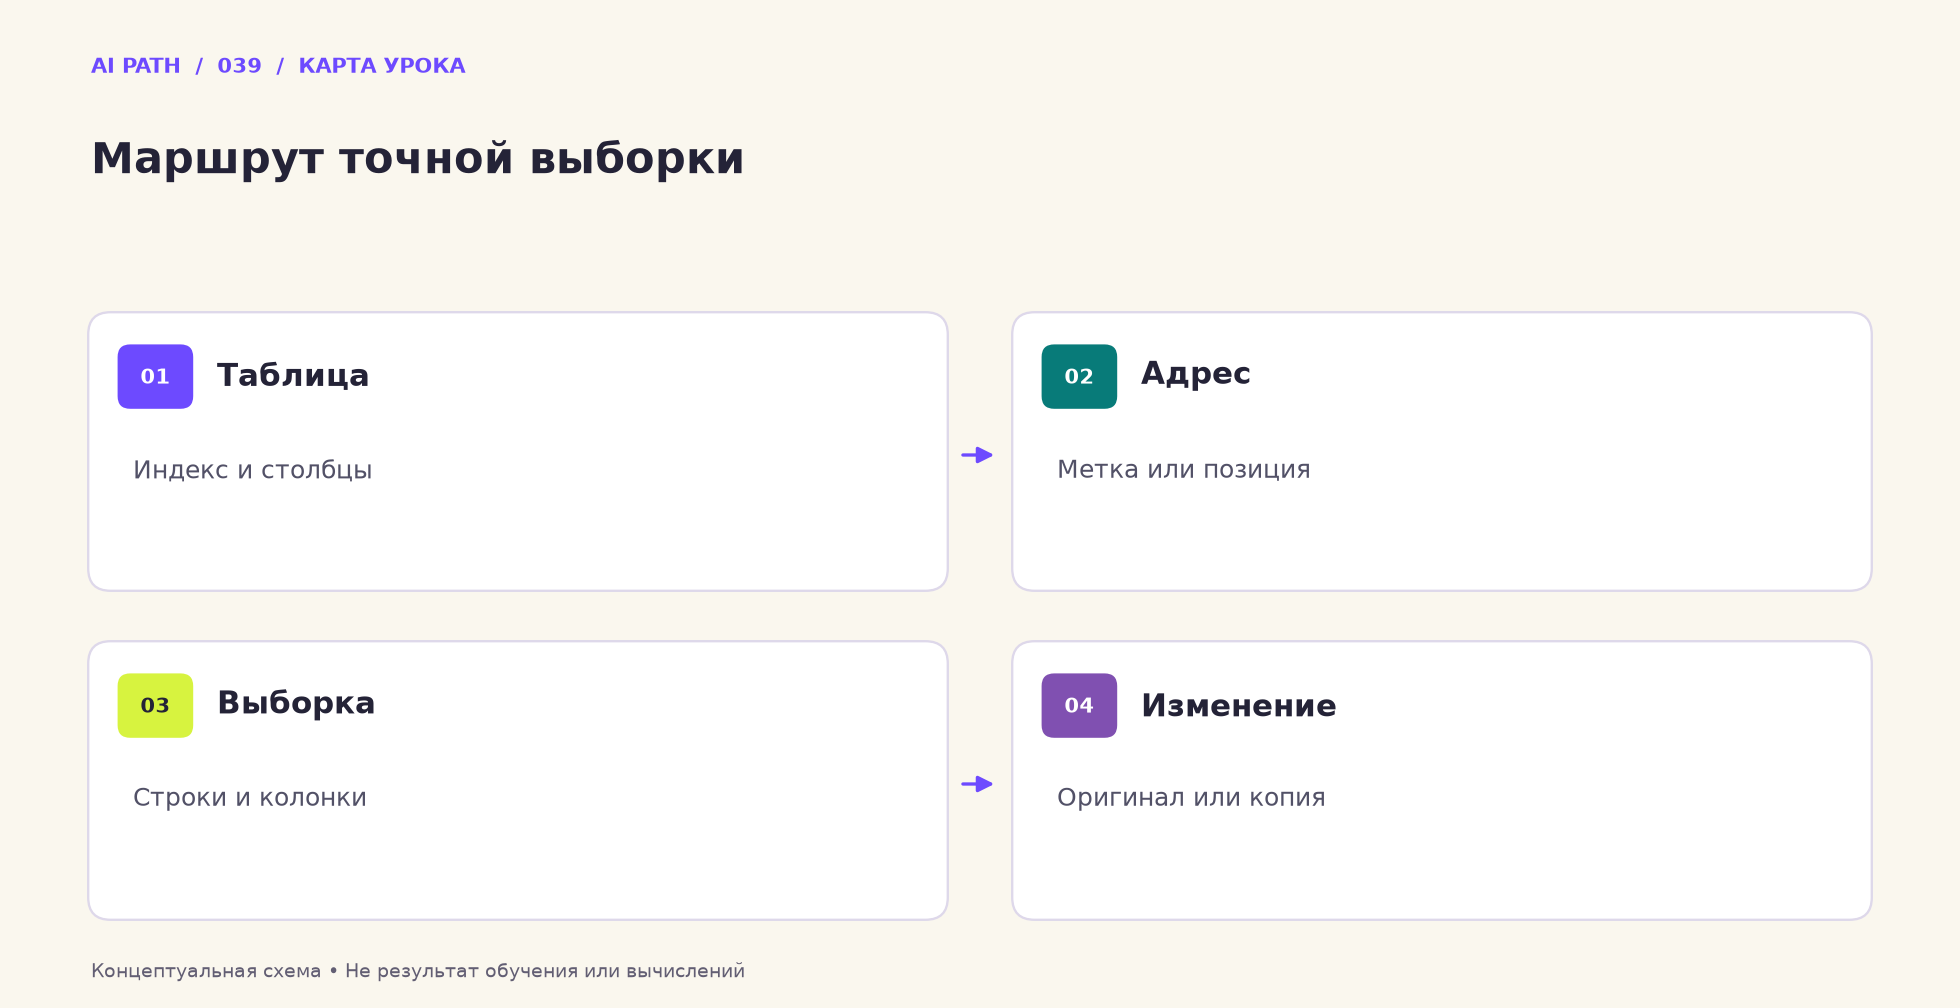

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Таблица** — Индекс и столбцы
2. **Адрес** — Метка или позиция
3. **Выборка** — Строки и колонки
4. **Изменение** — Оригинал или копия

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/Pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="ai-039-section-01"></a>
## 01 · Таблица с датами

Проследите связь между индексом, столбцами и отдельной Series.

_Далее — исходные ячейки учебного материала._

In [13]:
import pandas as pd
import numpy as np

dates = pd.date_range('1/1/2000', periods=8)
dates

DatetimeIndex(['2000-01-01', '2000-01-02', '2000-01-03', '2000-01-04',
               '2000-01-05', '2000-01-06', '2000-01-07', '2000-01-08'],
              dtype='datetime64[ns]', freq='D')

In [0]:
df = pd.DataFrame(np.random.randn(8, 4),index=dates, columns=['A', 'B', 'C', 'D'])

In [16]:
df

,A,B,C,D
2000-01-01,0.555078,-0.355258,1.087740,-1.379475
2000-01-02,-0.461858,0.268182,-2.066158,-0.793298
2000-01-03,1.074024,0.534992,-0.707917,-1.861931
2000-01-04,1.012391,-0.019112,0.716041,1.500299
2000-01-05,-1.160429,0.491771,0.018525,0.503604
2000-01-06,-0.088627,0.602497,-2.379933,0.082339
2000-01-07,-0.651125,1.074404,-1.172963,-0.607568
2000-01-08,0.705187,0.014330,-0.836342,1.297009


In [0]:
s = df['A'] # бырать столбец из таблицы

In [22]:
s[dates[5]] # 6 строка

-0.08862671748146218

In [23]:
df

,A,B,C,D
2000-01-01,0.555078,-0.355258,1.087740,-1.379475
2000-01-02,-0.461858,0.268182,-2.066158,-0.793298
2000-01-03,1.074024,0.534992,-0.707917,-1.861931
2000-01-04,1.012391,-0.019112,0.716041,1.500299
2000-01-05,-1.160429,0.491771,0.018525,0.503604
2000-01-06,-0.088627,0.602497,-2.379933,0.082339
2000-01-07,-0.651125,1.074404,-1.172963,-0.607568
2000-01-08,0.705187,0.014330,-0.836342,1.297009


In [0]:
df[['B', 'A']] = df[['A', 'B']]

In [25]:
df

,A,B,C,D
2000-01-01,-0.355258,0.555078,1.087740,-1.379475
2000-01-02,0.268182,-0.461858,-2.066158,-0.793298
2000-01-03,0.534992,1.074024,-0.707917,-1.861931
2000-01-04,-0.019112,1.012391,0.716041,1.500299
2000-01-05,0.491771,-1.160429,0.018525,0.503604
2000-01-06,0.602497,-0.088627,-2.379933,0.082339
2000-01-07,1.074404,-0.651125,-1.172963,-0.607568
2000-01-08,0.014330,0.705187,-0.836342,1.297009


<a id="ai-039-section-02"></a>
## 02 · Копия и изменение

Проверьте, что именно меняется при присваивании в Series и DataFrame.

_Далее — исходные ячейки учебного материала._

In [0]:
sa = pd.Series([1, 2, 3], index=list('abc'))

In [27]:
sa

a    1
b    2
c    3
dtype: int64

In [0]:
dfa = df.copy()

In [30]:
sa.b

2

In [33]:
dfa.C

2000-01-01    1.087740
2000-01-02   -2.066158
2000-01-03   -0.707917
2000-01-04    0.716041
2000-01-05    0.018525
2000-01-06   -2.379933
2000-01-07   -1.172963
2000-01-08   -0.836342
Freq: D, Name: C, dtype: float64

In [0]:
sa.a = 5 # присвоить значение индексу a

In [35]:
sa

a    5
b    2
c    3
dtype: int64

In [0]:
dfa.A = list(range(len(dfa.index)))

In [37]:
dfa

,A,B,C,D
2000-01-01,0,0.555078,1.087740,-1.379475
2000-01-02,1,-0.461858,-2.066158,-0.793298
2000-01-03,2,1.074024,-0.707917,-1.861931
2000-01-04,3,1.012391,0.716041,1.500299
2000-01-05,4,-1.160429,0.018525,0.503604
2000-01-06,5,-0.088627,-2.379933,0.082339
2000-01-07,6,-0.651125,-1.172963,-0.607568
2000-01-08,7,0.705187,-0.836342,1.297009


In [0]:
dfa['A'] = list(range(len(dfa.index)))

In [40]:
dfa

,A,B,C,D
2000-01-01,0,0.555078,1.087740,-1.379475
2000-01-02,1,-0.461858,-2.066158,-0.793298
2000-01-03,2,1.074024,-0.707917,-1.861931
2000-01-04,3,1.012391,0.716041,1.500299
2000-01-05,4,-1.160429,0.018525,0.503604
2000-01-06,5,-0.088627,-2.379933,0.082339
2000-01-07,6,-0.651125,-1.172963,-0.607568
2000-01-08,7,0.705187,-0.836342,1.297009


<a id="ai-039-section-03"></a>
## 03 · Создание столбца

Отличайте добавление через квадратные скобки от присваивания атрибута.

_Далее — исходные ячейки учебного материала._

In [47]:
x = pd.DataFrame({'x': [1, 2,2, 3], 'y': [3, 4,2, 5]})
x

,x,y
0,1,3
1,2,4
2,2,2
3,3,5


In [0]:
df = pd.DataFrame({'one': [1., 2., 3.]})

In [49]:
df.two = [4, 5, 6]

/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  """Entry point for launching an IPython kernel.


In [50]:
df

,one
0,1.0
1,2.0
2,3.0


<a id="ai-039-section-04"></a>
## 04 · Срезы

Сопоставьте шаг, обратный порядок и изменение выбранной части.

_Далее — исходные ячейки учебного материала._

In [52]:
s[:6]

2000-01-01   -0.355258
2000-01-02    0.268182
2000-01-03    0.534992
2000-01-04   -0.019112
2000-01-05    0.491771
2000-01-06    0.602497
Freq: D, Name: A, dtype: float64

In [53]:
s[::2]

2000-01-01   -0.355258
2000-01-03    0.534992
2000-01-05    0.491771
2000-01-07    1.074404
Freq: 2D, Name: A, dtype: float64

In [54]:
s[::-1]


2000-01-08    0.014330
2000-01-07    1.074404
2000-01-06    0.602497
2000-01-05    0.491771
2000-01-04   -0.019112
2000-01-03    0.534992
2000-01-02    0.268182
2000-01-01   -0.355258
Freq: -1D, Name: A, dtype: float64

In [0]:
s2 = s.copy()

In [0]:
s2[:5] = 0

In [58]:
s2[:6]

2000-01-01    0.000000
2000-01-02    0.000000
2000-01-03    0.000000
2000-01-04    0.000000
2000-01-05    0.000000
2000-01-06    0.602497
Freq: D, Name: A, dtype: float64

In [59]:
df[:3]

,one
0,1.0
1,2.0
2,3.0


In [60]:
df[::-1]

,one
2,3.0
1,2.0
0,1.0


<a id="ai-039-section-05"></a>
## 05 · Временной индекс

Выберите интервал по датам и проверьте его границы.

_Далее — исходные ячейки учебного материала._

In [0]:
 dfl = pd.DataFrame(np.random.randn(365, 6),
                      columns=list('ABCDEF'),
                      index=pd.date_range('20130101', periods=365))

In [69]:
dfl

,A,B,C,D,E,F
2013-01-01,-0.595830,-0.486437,0.062945,0.670677,-0.286615,-0.481155
2013-01-02,0.941682,0.301323,-1.020600,-0.623978,-0.319138,-0.471905
2013-01-03,-0.099363,-0.422536,-0.136562,-1.164670,-0.963621,-1.104442
2013-01-04,2.316417,0.896544,0.226817,-0.604550,-0.099547,-0.880768
2013-01-05,1.134990,-0.680754,-0.358409,0.793169,-0.584481,-0.155898
...,...,...,...,...,...,...
2013-12-27,0.330810,0.210216,-0.507749,-1.064140,0.022806,-0.067834
2013-12-28,0.000016,-0.517453,-1.113911,-1.353657,-0.374223,-1.049328
2013-12-29,0.997969,-1.375239,-1.190721,0.339995,0.012204,0.046467
2013-12-30,1.568723,1.337749,-0.268788,0.497521,1.143063,0.987473


In [71]:
dfl.loc['20130102':'20130604']

,A,B,C,D,E,F
2013-01-02,0.941682,0.301323,-1.020600,-0.623978,-0.319138,-0.471905
2013-01-03,-0.099363,-0.422536,-0.136562,-1.164670,-0.963621,-1.104442
2013-01-04,2.316417,0.896544,0.226817,-0.604550,-0.099547,-0.880768
2013-01-05,1.134990,-0.680754,-0.358409,0.793169,-0.584481,-0.155898
2013-01-06,0.620415,0.127671,-1.233715,-1.380595,-0.760926,0.715594
...,...,...,...,...,...,...
2013-05-31,-1.181267,0.231997,-1.519500,0.295264,0.415034,-1.308745
2013-06-01,1.071147,-0.442552,1.356161,0.056077,1.251336,0.035168
2013-06-02,-0.396261,-0.126438,1.256858,0.548086,0.415023,1.219475
2013-06-03,0.811962,1.109666,-0.285040,-0.099937,-1.603486,0.685745


<a id="ai-039-section-06"></a>
## 06 · Выборка loc

Метки в loc задают диапазон с включением конечной метки.

_Далее — исходные ячейки учебного материала._

In [0]:
s1 = pd.Series(np.random.randn(6), index=list('abcdef'))

In [73]:
s1

a    1.291644
b   -0.667899
c   -0.523120
d    1.238864
e   -0.361251
f    0.578317
dtype: float64

In [74]:
s1.loc['c':]

c   -0.523120
d    1.238864
e   -0.361251
f    0.578317
dtype: float64

In [75]:
s1.loc['b':'e'] # выбрать срочки

b   -0.667899
c   -0.523120
d    1.238864
e   -0.361251
dtype: float64

In [76]:
s1.loc['b']

-0.6678986507935434

In [77]:
s1.loc['c':] = 0
s1

a    1.291644
b   -0.667899
c    0.000000
d    0.000000
e    0.000000
f    0.000000
dtype: float64

<a id="ai-039-section-07"></a>
## 07 · Две оси сразу

Постройте выборку строк и столбцов, затем проверьте скаляр и булеву маску.

_Далее — исходные ячейки учебного материала._

In [82]:
df1 = pd.DataFrame(np.random.randn(6, 4),
                        index=list('123456'),
                        columns=list('ABCD')) 
df1

,A,B,C,D
1,-1.736693,-0.907305,0.450869,-0.274803
2,0.067124,-1.311043,-0.833772,-0.084714
3,0.682857,-0.838862,-0.158005,-0.816414
4,0.505483,-0.160212,0.747966,0.543714
5,-0.839764,-0.345969,0.407231,-0.313532
6,-0.103112,-0.237337,0.578957,2.322219


In [86]:
df1.loc[['1', '2', '3'],:]

,A,B,C,D
1,-1.736693,-0.907305,0.450869,-0.274803
2,0.067124,-1.311043,-0.833772,-0.084714
3,0.682857,-0.838862,-0.158005,-0.816414


In [88]:
df1.loc['4':, 'A':'D']

,A,B,C,D
4,0.505483,-0.160212,0.747966,0.543714
5,-0.839764,-0.345969,0.407231,-0.313532
6,-0.103112,-0.237337,0.578957,2.322219


In [91]:
df1.loc['1',:] # строку перевенули в столбец 

A   -1.736693
B   -0.907305
C    0.450869
D   -0.274803
Name: 1, dtype: float64

In [93]:
 df1.loc['1'] > 0

A    False
B    False
C     True
D    False
Name: 1, dtype: bool

In [95]:
df1.loc[:, df1.loc['2'] > 0] # нати положительное значение среди всех столбцов в индексе 2

,A
1,-1.736693
2,0.067124
3,0.682857
4,0.505483
5,-0.839764
6,-0.103112


In [96]:
df1.loc['1', 'A']  # получание значения индекс - поле

-1.7366930952548882

In [99]:
s = pd.Series(list('abcde'), index=[0, 3, 2, 5, 4])
s

0    a
3    b
2    c
5    d
4    e
dtype: object

In [101]:
s.loc[3:4]

3    b
2    c
5    d
4    e
dtype: object

<a id="ai-039-practice"></a>
## Проверьте понимание

1. Какие строки входят в loc['b':'e'] и почему?
2. Создаёт ли df.two новый столбец при отсутствии такого столбца?
3. Чем loc[3:4] отличается от iloc[3:4] при индексе [0,3,2,5,4]?

### Один самостоятельный эксперимент

На последней Series сравните одинаково записанные диапазоны loc и iloc.

**Критерий успеха:** Для каждой выборки перечислены метки и позиции; различие объяснено без опоры на случайные значения.

<a id="ai-039-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/Pandas/Pandas.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Присваивание df.two в ячейке 22 может создать атрибут вместо столбца; используемый пример требует внимательной интерпретации.
- Имена df и s повторно используются; запуск ячеек вне порядка меняет смысл примеров.
- Случайные значения не фиксируются seed, поэтому числа вывода могут отличаться; новая проверка выполнения не проводилась.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.